In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Настраиваем стиль
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Загружаем данные
df = pd.read_csv('../data/sales.csv')

# Классификация признаков
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numerical_cols = df.select_dtypes(exclude=['object']).columns.tolist()

print(f"Всего признаков: {df.shape[1]}")
print(f"Категориальные ({len(categorical_cols)} шт): {categorical_cols}")
print(f"Числовые ({len(numerical_cols)} шт): {numerical_cols}")

Всего признаков: 17
Категориальные (9 шт): ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Date', 'Time', 'Payment']
Числовые (8 шт): ['Unit price', 'Quantity', 'Tax 5%', 'Sales', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


C:\Users\user\AppData\Local\Temp\ipykernel_12708\3066255728.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


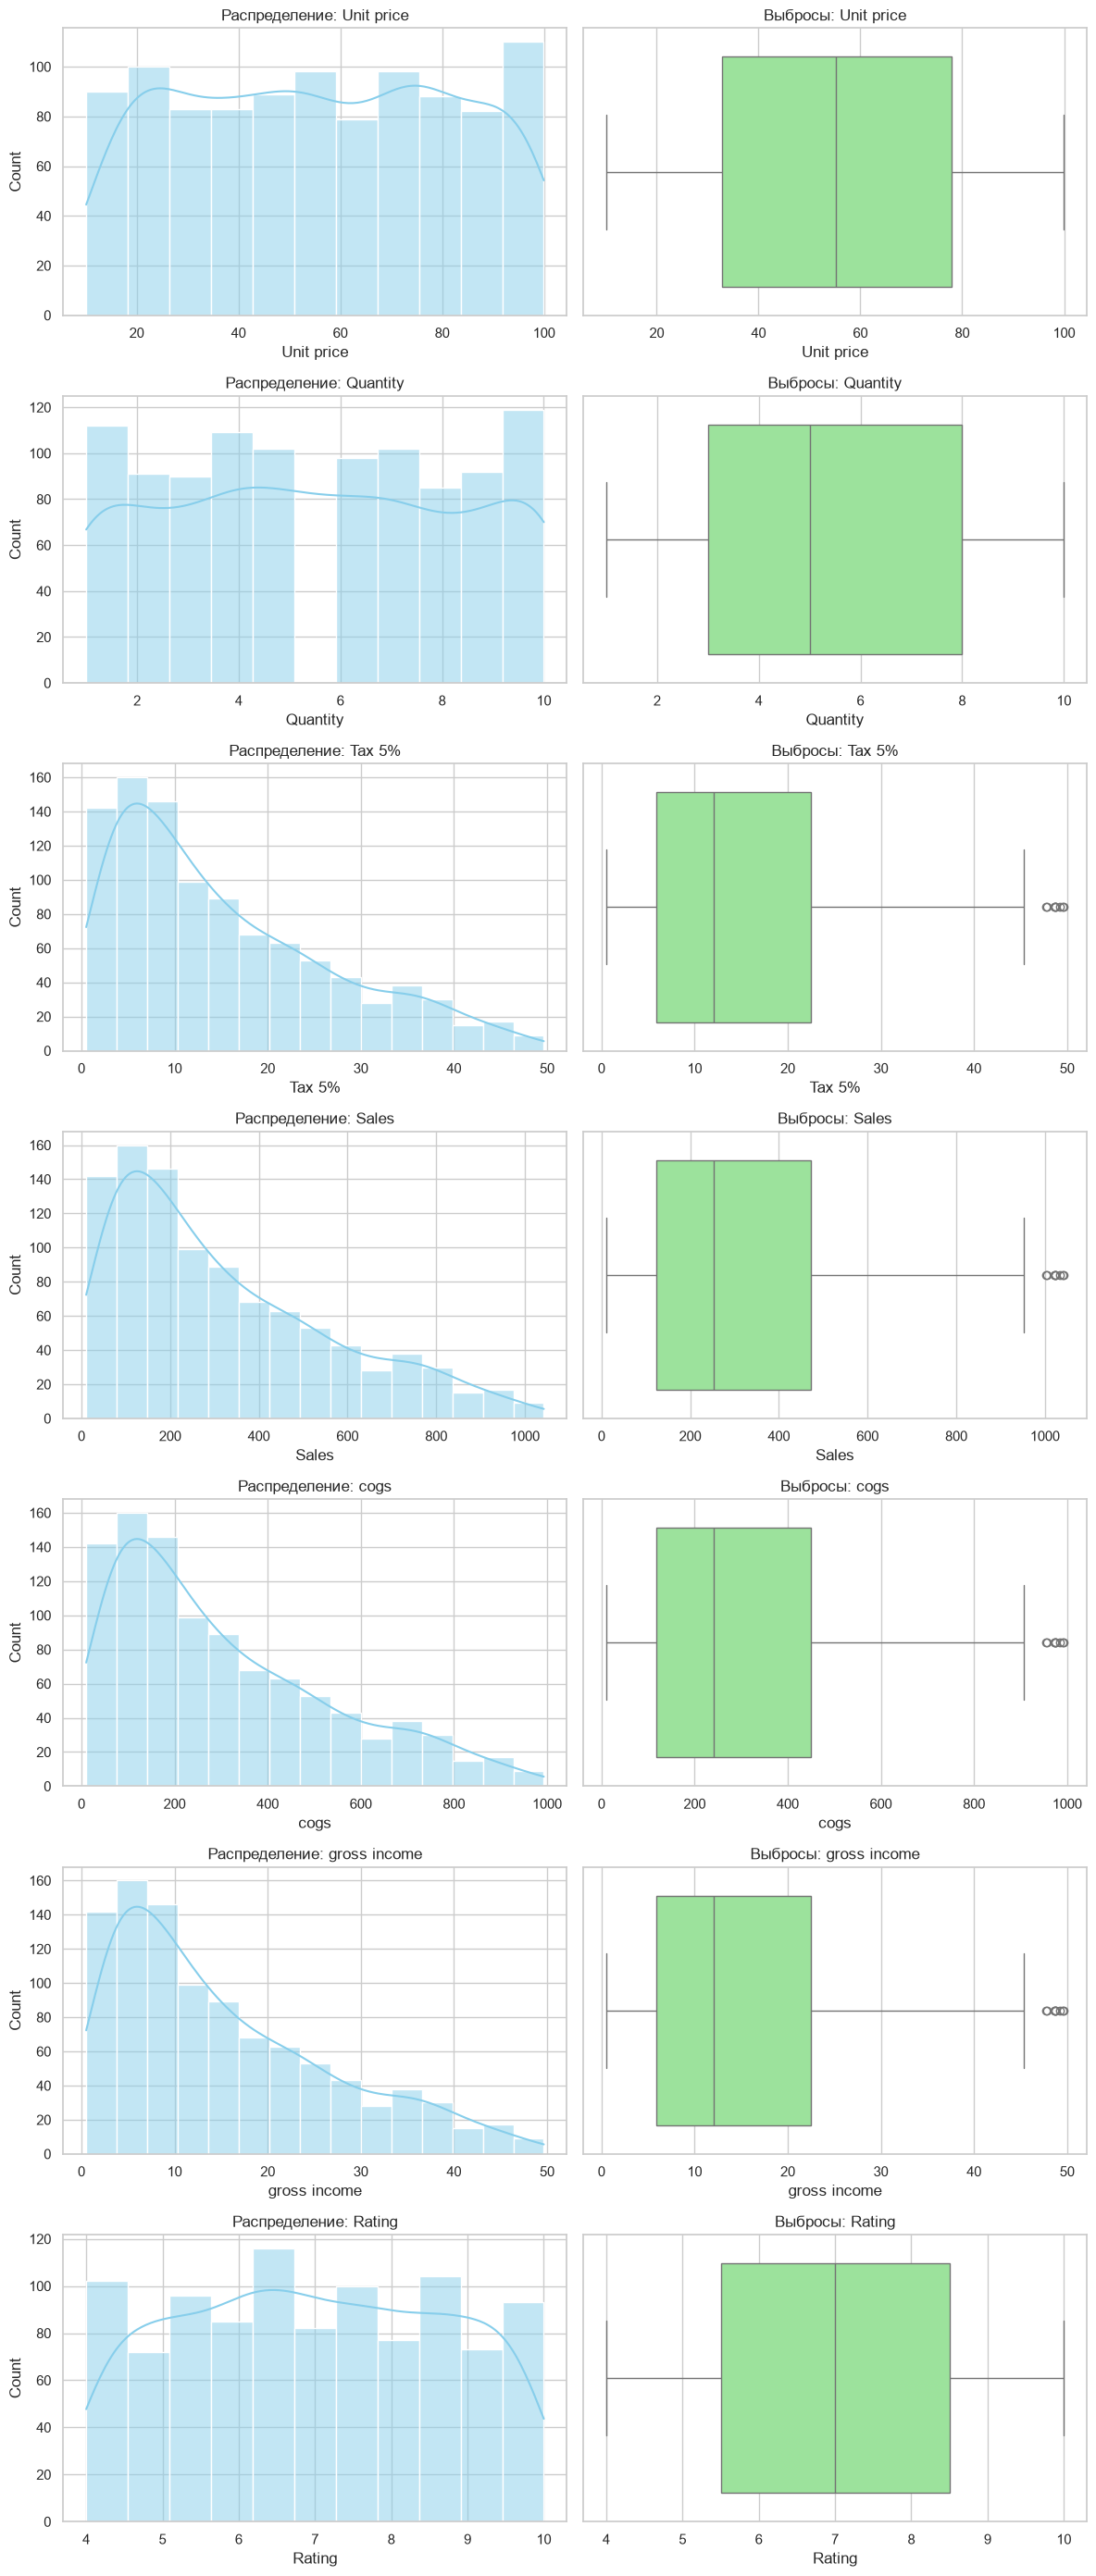

In [2]:
# Уберем 'gross margin percentage', так как мы уже знаем, что она константная
num_cols_to_plot = [col for col in numerical_cols if col != 'gross margin percentage']

# Строим гистограммы и боксплоты для числовых признаков
fig, axes = plt.subplots(len(num_cols_to_plot), 2, figsize=(12, 4 * len(num_cols_to_plot)))

for i, col in enumerate(num_cols_to_plot):
    # Гистограмма (распределение)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Распределение: {col}')
    
    # Боксплот (поиск выбросов)
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Выбросы: {col}')

plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_12708\2859629869.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, ax=axes[i], palette='Set2')
C:\Users\user\AppData\Local\Temp\ipykernel_12708\2859629869.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, ax=axes[i], palette='Set2')
C:\Users\user\AppData\Local\Temp\ipykernel_12708\2859629869.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, ax=axes[i], palette='Set2')
C:\Users\user\AppData\Local\Temp\ipykernel_12708\2859629869.py:8: FutureW

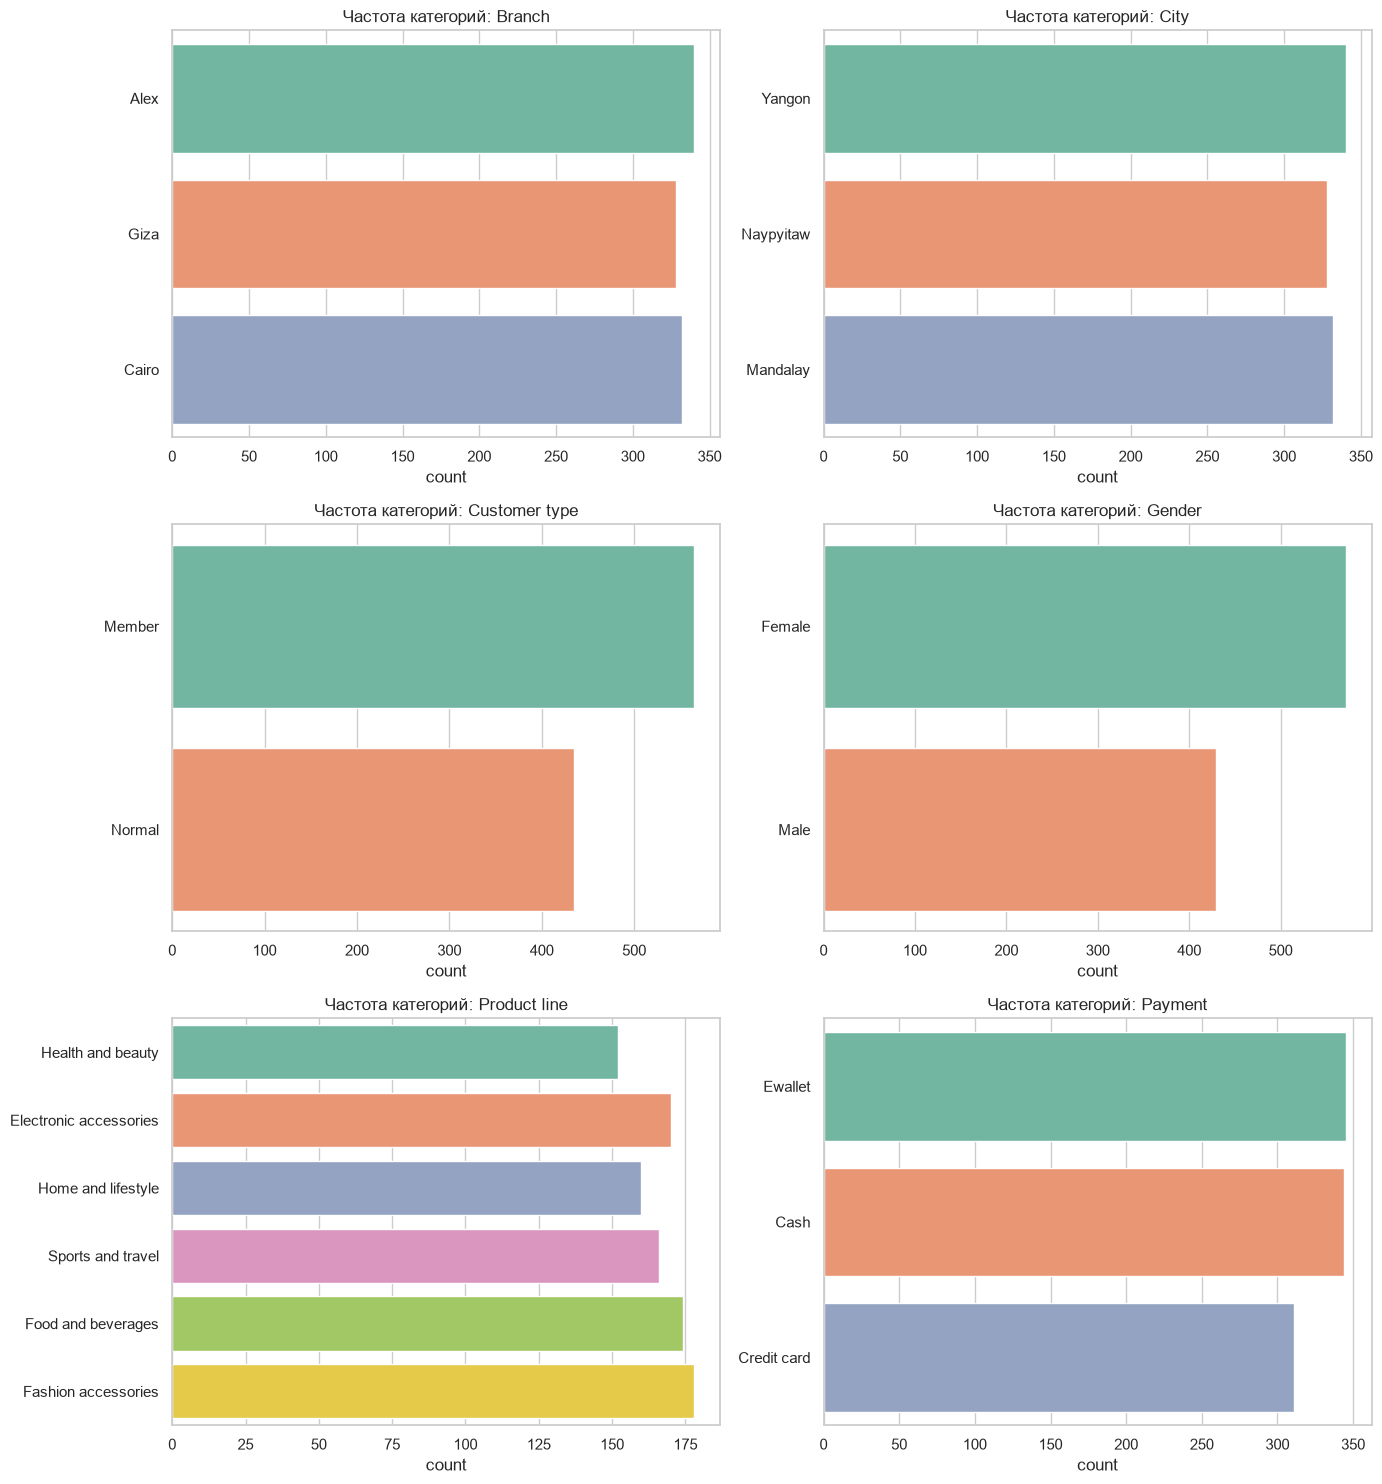

In [3]:
# Исключим Invoice ID, Date и Time, так как там слишком много уникальных значений
cat_cols_to_plot = [c for c in categorical_cols if c not in ['Invoice ID', 'Date', 'Time']]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, col in enumerate(cat_cols_to_plot):
    sns.countplot(data=df, y=col, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Частота категорий: {col}')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

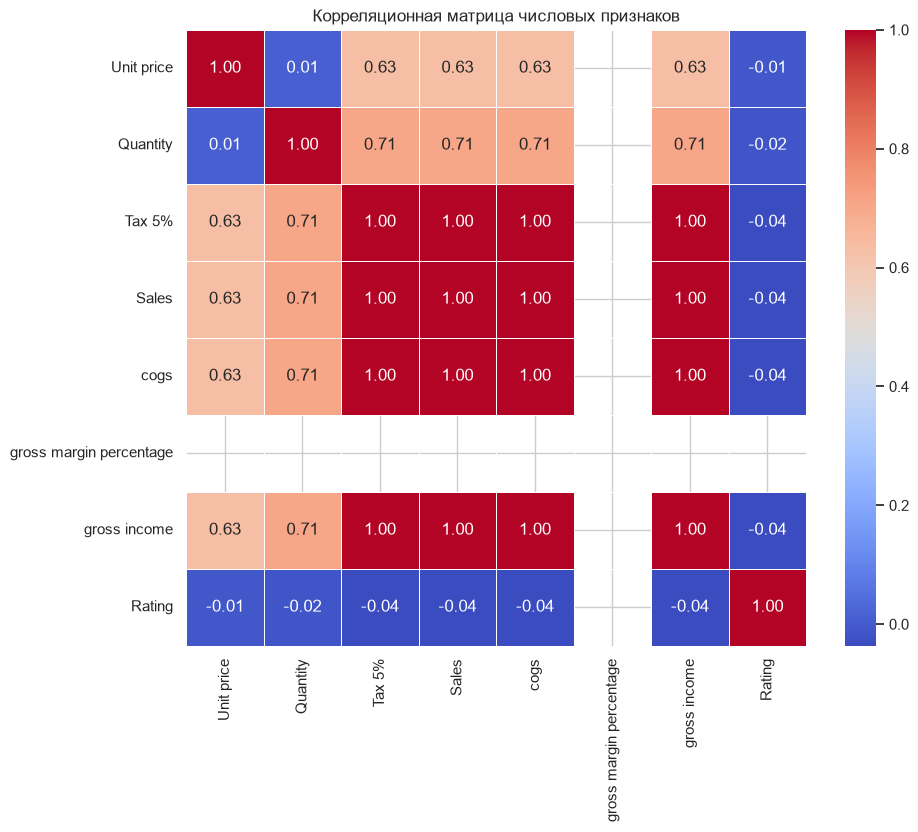

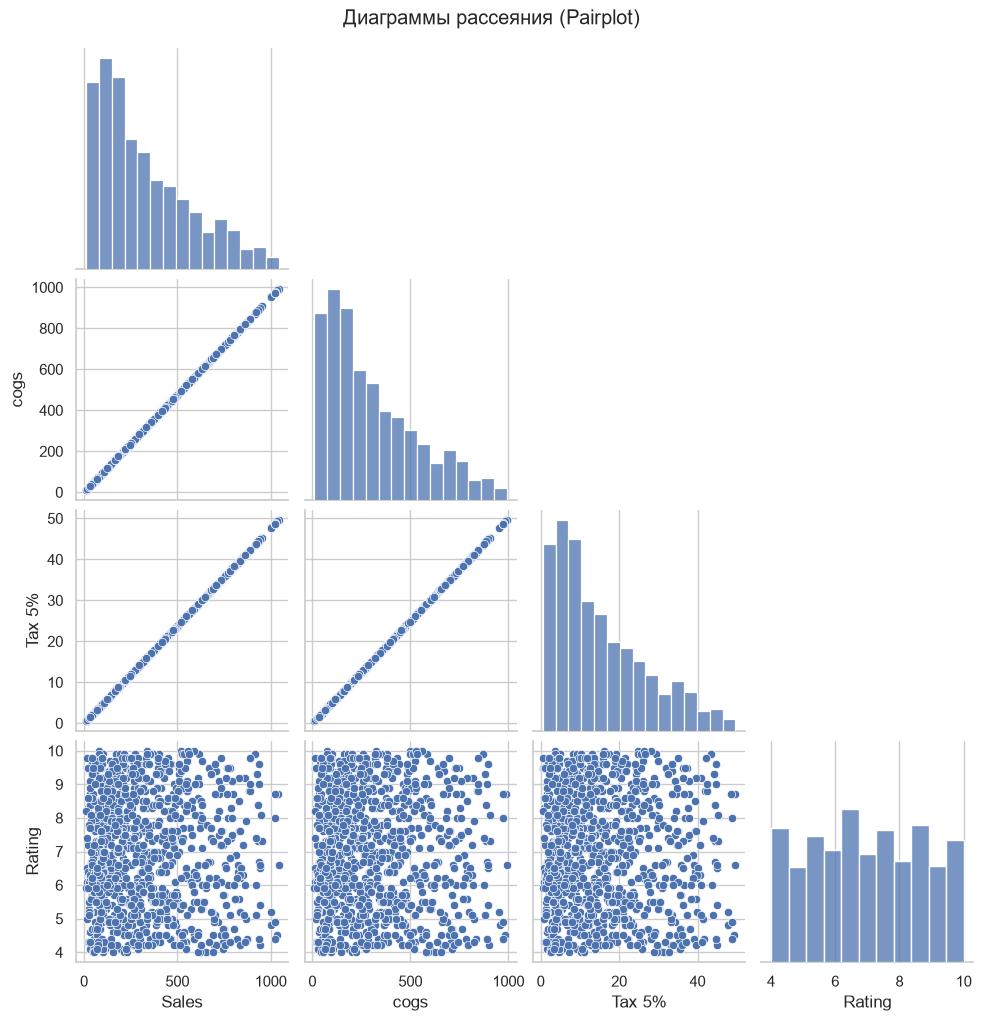

In [4]:
# Строим матрицу корреляций
plt.figure(figsize=(10, 8))
corr_matrix = df[numerical_cols].corr()

# Тепловая карта
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

# Мы увидим, что Tax 5%, Sales, cogs и gross income имеют корреляцию 1.0 (идеальная зависимость).
# Построим pairplot для этих сильно скоррелированных пар + Rating для сравнения
highly_correlated = ['Sales', 'cogs', 'Tax 5%', 'Rating']
sns.pairplot(df[highly_correlated], corner=True)
plt.suptitle('Диаграммы рассеяния (Pairplot)', y=1.02)
plt.show()

Распределение целевой переменной (Customer type):


,Количество,Процент (%)
Customer type,,
Member,565,56.5
Normal,435,43.5


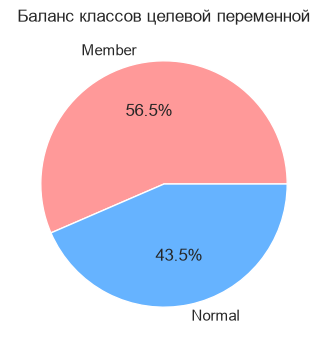

In [5]:
# Оценка дисбаланса целевой переменной
target = 'Customer type'

counts = df[target].value_counts()
percentages = df[target].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({'Количество': counts, 'Процент (%)': percentages})
print("Распределение целевой переменной (Customer type):")
display(balance_df)

plt.figure(figsize=(6, 4))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
plt.title('Баланс классов целевой переменной')
plt.show()

### Отчёт по результатам EDA (проблемы и пути решения)

В ходе разведочного анализа были выявлены следующие особенности и проблемы в данных, которые необходимо устранить на этапе предобработки (следующее занятие):

1. **Мультиколлинеарность числовых признаков:** Признаки `Sales`, `cogs`, `Tax 5%` и `gross income` имеют идеальную корреляцию (коэффициент = 1.0), так как рассчитываются друг из друга. *Решение:* Оставить только один базовый признак (например, `Sales`), остальные удалить, чтобы не переобучать будущую модель.
2. **Константные признаки:** Столбец `gross margin percentage` содержит одно и то же значение (4.76%) для всех строк. *Решение:* Удалить данный столбец, так как он не обладает дисперсией и не несет полезной информации.
3. **Неверные типы данных:** Признаки `Date` (дата) и `Time` (время) имеют строковый тип (`object`). *Решение:* Преобразовать их в формат `datetime` для возможности извлечения месяца, дня недели или часа покупки.
4. **Бесполезные идентификаторы:** Столбец `Invoice ID` является уникальным номером чека и не содержит паттернов для анализа. *Решение:* Сбросить его (drop) перед обучением модели.
5. **Наличие выбросов:** На боксплотах признаков `Sales` и `cogs` наблюдаются тяжелые "правые хвосты" (выбросы в виде очень крупных покупок). *Решение:* Оставить как есть, так как это естественные аномалии для ритейла, либо применить логарифмирование, если модель будет чувствительна к выбросам.
6. **Кодирование категорий:** Алгоритмы машинного обучения не понимают текст. *Решение:* Применить One-Hot Encoding для номинальных признаков (`Branch`, `City`, `Product line`) и Label Encoding для бинарных (`Gender`, `Customer type`).
7. **Баланс классов:** Целевая переменная `Customer type` (Member / Normal) сбалансирована идеально (50.1% на 49.9%). *Решение:* Применять специальные техники балансировки (SMOTE или взвешивание классов) не потребуется, можно использовать стандартную метрику Accuracy.